In [2]:
%load_ext autoreload
%autoreload 2
import emcee
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
from sklearn.metrics import r2_score
import pickle
from multiprocessing import Pool

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot
from statistics_functions import chi_squared
from cluster_error_prop import T500_from_L500

In [3]:
with open('data/equilibrium_clusters.pkl', 'rb') as file:
    # Load the data into nfws_subset variable
    nfws_subset = pickle.load(file)

In [4]:
len(nfws_subset)

49

In [5]:
mchi=1e-2
sigma0=9.3*1e-28

In [6]:
dm_cooling_rates = []
rad_cooling_rates = []
for n in nfws_subset: 
    dm_cooling_rates.append(n.integrated_dm_cooling_rate(0.001*n.R500,
                                                               n.R500,
                                                               sigma0,
                                                               mchi,)) # in erg/s/cm2
    rad_cooling_rates.append(n.total_cooling_rate(0.001*n.R500,
                                                  n.R500,
                                                  vol_rate='gfe'))

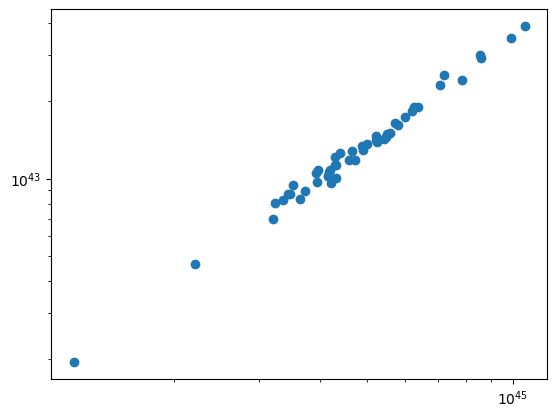

In [7]:
plt.scatter(rad_cooling_rates, dm_cooling_rates)
plt.xscale('log')
plt.yscale('log')

Text(0, 0.5, 'dm cooling rate/rad cooling rate')

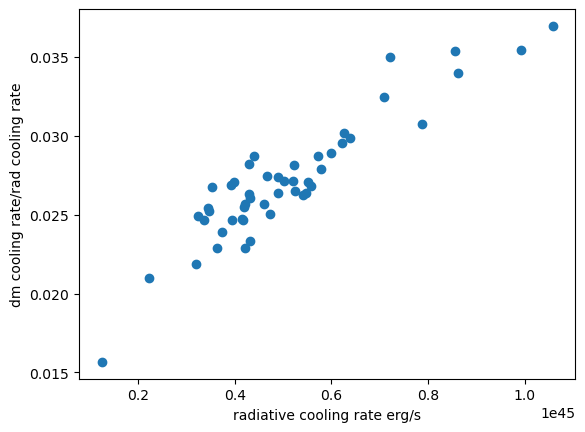

In [8]:
plt.scatter(rad_cooling_rates, np.divide(dm_cooling_rates,rad_cooling_rates))
plt.xlabel('radiative cooling rate erg/s')
plt.ylabel('dm cooling rate/rad cooling rate')
#plt.xscale('log')
#plt.yscale('log')

In [9]:
np.min(np.divide(dm_cooling_rates,rad_cooling_rates))

In [10]:
np.max(np.divide(dm_cooling_rates,rad_cooling_rates))

In [15]:
error_bars = [(r.plus + r.minus)/2  for r in rad_cooling_rates]

Text(0, 0.5, 'error bar/rad cooling rate')

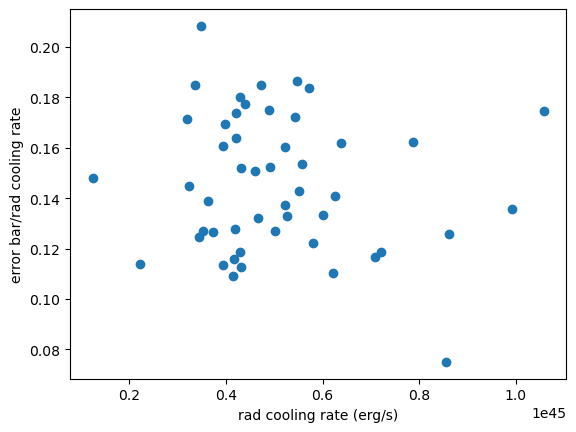

In [19]:
plt.scatter(rad_cooling_rates, np.divide(error_bars,rad_cooling_rates))
plt.xlabel('rad cooling rate (erg/s)')
plt.ylabel('error bar/rad cooling rate')

In [21]:
np.mean(np.divide(error_bars,rad_cooling_rates))